# Actividad 06 (Segunda unidad) — Detección de objetos con YOLO
### Comparación con la perspectiva de los R-CNN

**Objetivo:** comparar la tarea de detección de objetos desde la perspectiva de los **R-CNN** (dos etapas) y **YOLO** (una etapa), desarrollando una **aplicación de detección de objetos basada en YOLO** que trabaja sobre imágenes, ejecutable en **Google Colab**.

Las dos imágenes de la actividad (una **calle concurrida** y un **estacionamiento**) ya vienen incrustadas en este cuaderno, por lo que **no hace falta subir nada** para obtener los resultados.

| # | Sección | Qué entrega |
|---|---|---|
| 1 | Preparación | Dependencias, GPU, carga de las 2 imágenes |
| 2 | Fundamento teórico | YOLO vs R-CNN |
| 3 | Aplicación YOLO | Clase `DetectorYOLO` reutilizable (detección, tablas, recortes, exportación) |
| 4 | Resultados | Detección sobre ambas imágenes, estadísticas, galería de recortes |
| 5 | Experimentos | Tamaño de modelo, umbral de confianza, NMS, resolución |
| 6 | Casos de uso | Análisis de la calle (personas/vehículos/mapa de calor) y del estacionamiento (ocupación + color) |
| 7 | Comparación con R-CNN | Faster R-CNN sobre las mismas imágenes, emparejamiento por IoU |
| 8 | Aplicación interactiva | Interfaz web con Gradio (subir imagen, elegir modelo y umbrales) |
| 9 | Exportación | Imágenes anotadas, CSV y ZIP |
| 10 | Conclusiones | Resumen automático + análisis |

> **Cómo ejecutar:** *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)* y luego *Ejecutar todo*.

## 1. Preparación del entorno

In [ ]:
!pip -q install ultralytics gradio

In [2]:
import os, time, glob, json, base64, zipfile, warnings
from dataclasses import dataclass
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ultralytics import YOLO

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": False})

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", "GPU → " + torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU (activa la GPU para mayor velocidad)")

# Parámetros globales de la aplicación
MODELO_PRINCIPAL = "yolo11s.pt"   # n (rápido) · s (equilibrado) · m (más preciso)
CONF   = 0.25                     # umbral mínimo de confianza
IOU    = 0.70                     # umbral IoU para NMS
IMGSZ  = 640                      # lado mayor de entrada a la red
SALIDA = "resultados"; os.makedirs(SALIDA, exist_ok=True)

Dispositivo: CPU (activa la GPU para mayor velocidad)


### 1.1 Imágenes de la actividad
Las dos imágenes proporcionadas se guardan en la carpeta `imagenes/` desde el propio cuaderno. Si además quieres probar con imágenes propias, pon `SUBIR_PROPIAS = True`.

In [3]:
#@title Imágenes de la actividad (incrustadas en el cuaderno)
IMG_B64 = {
    "calle.jpg": "...",
    "estacionamiento.jpg": "...",
}
IMG_DIR = "imagenes"; os.makedirs(IMG_DIR, exist_ok=True)
for nombre, datos in IMG_B64.items():
    with open(os.path.join(IMG_DIR, nombre), "wb") as f:
        f.write(base64.b64decode(datos))
print("Imágenes de la actividad guardadas en", IMG_DIR)

Imágenes de la actividad guardadas en imagenes


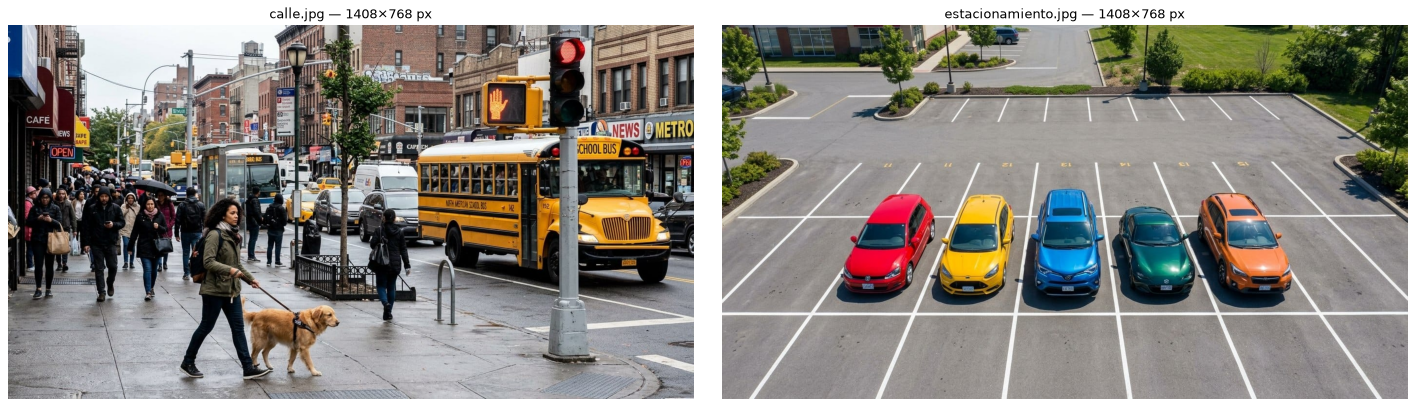

In [4]:
SUBIR_PROPIAS = False   #@param {type:"boolean"}
if SUBIR_PROPIAS:
    from google.colab import files
    for nombre, datos in files.upload().items():
        with open(os.path.join(IMG_DIR, nombre), "wb") as f: f.write(datos)

IMAGES = sorted(glob.glob(os.path.join(IMG_DIR, "*.jpg")) + glob.glob(os.path.join(IMG_DIR, "*.png")) + glob.glob(os.path.join(IMG_DIR, "*.jpeg")))

fig, ax = plt.subplots(1, len(IMAGES), figsize=(9 * len(IMAGES), 5))
ax = np.atleast_1d(ax)
for a, p in zip(ax, IMAGES):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    a.imshow(im); a.axis("off"); a.set_title(f"{os.path.basename(p)} — {im.shape[1]}×{im.shape[0]} px")
plt.tight_layout(); plt.show()

## 2. Fundamento: dos filosofías para detectar objetos

**Detección de objetos = localizar (caja) + clasificar (clase) cada objeto de la imagen.**

**R-CNN / Fast R-CNN / Faster R-CNN — enfoque de dos etapas**
1. Se generan **propuestas de región** (Selective Search en R-CNN; una *Region Proposal Network* en Faster R-CNN).
2. Cada región se recorta/pooling (*RoI Pooling/Align*) y una segunda cabeza **clasifica y refina la caja**.

**YOLO (*You Only Look Once*) — enfoque de una etapa**
1. Toda la imagen pasa **una sola vez** por una CNN (backbone → neck multiescala → *head*).
2. La red predice **directamente** cajas y clases sobre mapas de características a varias escalas (YOLO11 es *anchor-free*).
3. Un paso final de **NMS** (*Non-Maximum Suppression*) elimina cajas duplicadas.

| Aspecto | R-CNN (Faster R-CNN) | YOLO |
|---|---|---|
| Etapas | 2 (propuestas → clasificación/refinamiento) | 1 (regresión directa) |
| Velocidad | Menor; la segunda etapa se repite por región | Muy alta, apta para tiempo real |
| Contexto | Cada región se evalúa por separado | La red ve la **imagen completa** al predecir |
| Objetos pequeños / muy juntos | Históricamente más robusto | La brecha se ha reducido con cuellos multiescala (FPN/PAN) |
| Complejidad de uso | Más componentes | Una sola red, API sencilla |
| Típico uso | Máxima precisión sin restricción de latencia | Video, robótica, edge, aplicaciones interactivas |

En las secciones siguientes se **mide** esta comparación sobre las dos imágenes de la actividad.

## 3. La aplicación: clase `DetectorYOLO`
Encapsula el modelo y ofrece una API única: detectar → tabla de detecciones → imagen anotada → recortes → exportación. Se reutiliza en todos los experimentos y en la interfaz web.

In [5]:
@dataclass
class Resultado:
    nombre: str
    imagen_rgb: np.ndarray
    anotada_rgb: np.ndarray
    df: pd.DataFrame
    tiempo_ms: float
    modelo: str
    params: dict

class DetectorYOLO:
    """Detector de objetos basado en YOLO (Ultralytics) con utilidades de análisis."""

    def __init__(self, pesos=MODELO_PRINCIPAL):
        self.pesos = pesos
        self.model = YOLO(pesos)
        self.names = self.model.names
        # calentamiento: la primera inferencia incluye inicialización
        self.model.predict(np.zeros((640, 640, 3), np.uint8), device=DEVICE, verbose=False)

    def detect(self, fuente, conf=CONF, iou=IOU, imgsz=IMGSZ, clases=None, agnostic=False, nombre=None):
        """`fuente`: ruta de imagen o array BGR (OpenCV). Devuelve un `Resultado`."""
        if isinstance(fuente, str):
            bgr, nombre = cv2.imread(fuente), nombre or os.path.basename(fuente)
        else:
            bgr, nombre = fuente, nombre or "imagen"
        t0 = time.perf_counter()
        r = self.model.predict(bgr, conf=conf, iou=iou, imgsz=imgsz, classes=clases,
                               agnostic_nms=agnostic, device=DEVICE, verbose=False)[0]
        ms = (time.perf_counter() - t0) * 1000

        b = r.boxes
        xyxy = b.xyxy.cpu().numpy() if len(b) else np.zeros((0, 4))
        df = pd.DataFrame({
            "clase": [self.names[int(c)] for c in b.cls],
            "confianza": b.conf.cpu().numpy().round(3) if len(b) else [],
            "x1": xyxy[:, 0].round(0), "y1": xyxy[:, 1].round(0),
            "x2": xyxy[:, 2].round(0), "y2": xyxy[:, 3].round(0),
        })
        df["ancho"], df["alto"] = df.x2 - df.x1, df.y2 - df.y1
        df["area"] = df.ancho * df.alto
        # Tamaño según COCO (pequeño < 32², mediano < 96², grande ≥ 96² px) con el área normalizada
        # a una imagen de 640 px de lado mayor, que es la escala de referencia de COCO.
        esc = (640 / max(bgr.shape[:2])) ** 2
        df["area_640"] = (df.area * esc).round(0)
        df["tamano"] = pd.cut(df.area_640, [0, 32**2, 96**2, np.inf],
                              labels=["pequeño", "mediano", "grande"]).astype(str)
        df = df.sort_values("confianza", ascending=False).reset_index(drop=True)
        df.insert(0, "id", np.arange(1, len(df) + 1))

        return Resultado(nombre, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), r.plot(line_width=2)[..., ::-1].copy(),
                         df, ms, self.pesos, dict(conf=conf, iou=iou, imgsz=imgsz, agnostic=agnostic))

    def tiempo_mediano(self, fuente, repeticiones=3, **kw):
        return float(np.median([self.detect(fuente, **kw).tiempo_ms for _ in range(repeticiones)]))

def mostrar_par(res, figsize=(20, 6)):
    fig, ax = plt.subplots(1, 2, figsize=figsize)
    ax[0].imshow(res.imagen_rgb); ax[0].set_title(f"Original — {res.nombre}", fontsize=13)
    ax[1].imshow(res.anotada_rgb)
    ax[1].set_title(f"{res.modelo}: {len(res.df)} detecciones · {res.tiempo_ms:.0f} ms", fontsize=13)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

def galeria_recortes(res, n=12, guardar_en=None, cols=6):
    sel = res.df.head(n)
    filas = int(np.ceil(len(sel) / cols))
    fig, ax = plt.subplots(filas, cols, figsize=(2.6 * cols, 2.9 * filas))
    ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis("off")
    for a, (_, d) in zip(ax, sel.iterrows()):
        crop = res.imagen_rgb[int(d.y1):int(d.y2), int(d.x1):int(d.x2)]
        a.imshow(crop); a.set_title(f"#{d.id} {d.clase} {d.confianza:.2f}", fontsize=10)
        if guardar_en:
            os.makedirs(guardar_en, exist_ok=True)
            cv2.imwrite(f"{guardar_en}/{res.nombre[:-4]}_{int(d.id):02d}_{d.clase}.jpg", crop[..., ::-1])
    plt.tight_layout(); plt.show()

yolo = DetectorYOLO(MODELO_PRINCIPAL)
print(f"Modelo cargado: {yolo.pesos} · {len(yolo.names)} clases COCO · {sum(p.numel() for p in yolo.model.model.parameters())/1e6:.1f} M parámetros")

Modelo cargado: yolo11s.pt · 80 clases COCO · 9.5 M parámetros


## 4. Resultados sobre las imágenes de la actividad

### 4.1 Detección con YOLO (umbral de confianza 0.25)

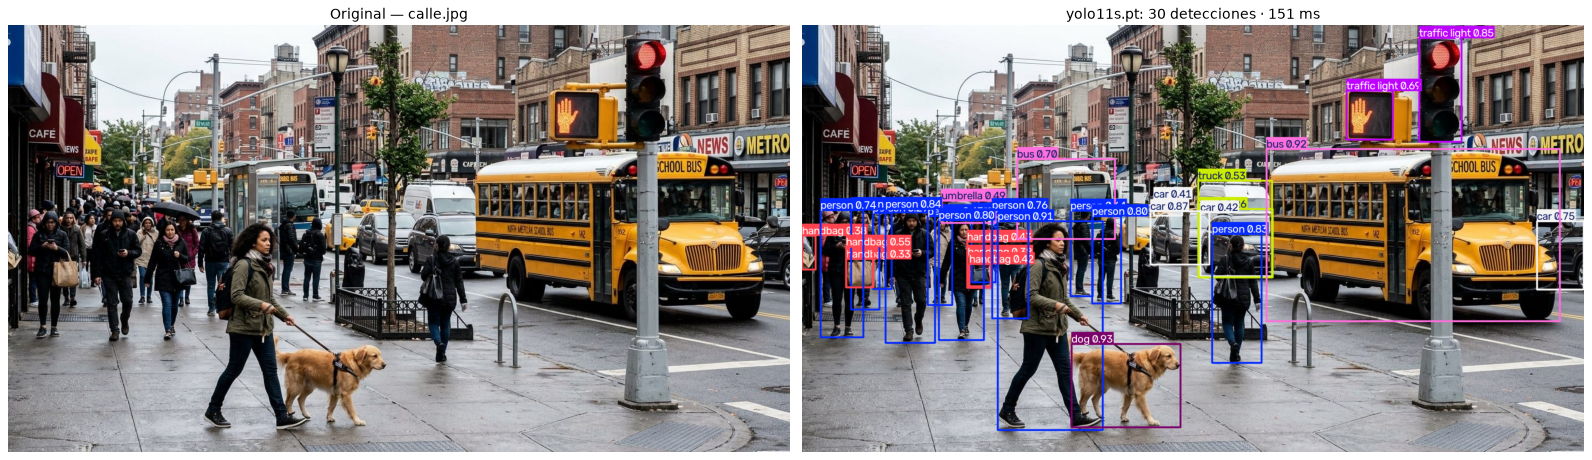

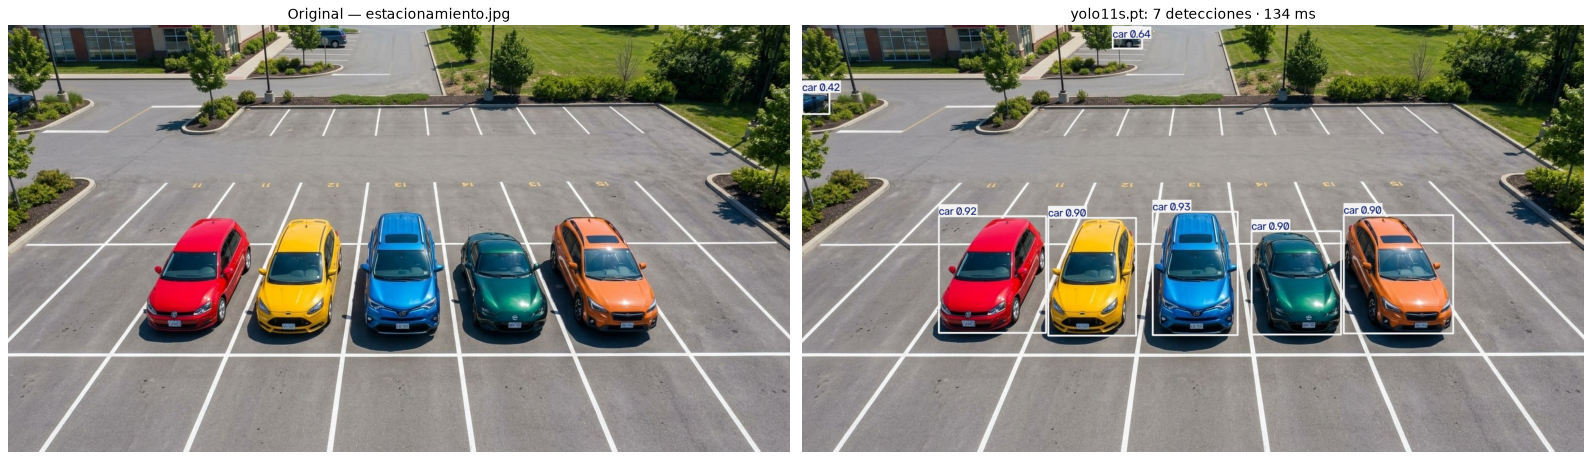

,imagen,modelo,detecciones,confianza media,tiempo (ms),clases
0,calle.jpg,yolo11s.pt,30,0.607,151.2,"{'dog': 1, 'bus': 2, 'person': 12, 'car': 4, 'traffic light': 2, 'handbag': 6, 'truck': 2, 'umbrella': 1}"
1,estacionamiento.jpg,yolo11s.pt,7,0.803,134.3,{'car': 7}


In [6]:
RES = {}
for p in IMAGES:
    RES[os.path.basename(p)] = yolo.detect(p)
    mostrar_par(RES[os.path.basename(p)])

resumen = pd.DataFrame([{
    "imagen": k, "modelo": r.modelo, "detecciones": len(r.df),
    "confianza media": round(r.df.confianza.mean(), 3), "tiempo (ms)": round(r.tiempo_ms, 1),
    "clases": dict(Counter(r.df.clase))} for k, r in RES.items()])
pd.set_option("display.max_colwidth", None)
display(resumen)

### 4.2 Tabla de detecciones (coordenadas, tamaño, confianza)

In [7]:
for k, r in RES.items():
    print(f"\n▶ {k}  —  {len(r.df)} detecciones")
    display(r.df.head(15))


▶ calle.jpg  —  30 detecciones


,id,clase,confianza,x1,y1,x2,y2,ancho,alto,area,area_640,tamano
0,1,dog,0.925,486.0,573.0,681.0,723.0,195.0,150.0,29250.0,6043.0,mediano
1,2,bus,0.918,836.0,222.0,1365.0,532.0,529.0,310.0,163990.0,33882.0,grande
2,3,person,0.909,353.0,353.0,541.0,728.0,188.0,375.0,70500.0,14566.0,grande
3,4,car,0.865,628.0,334.0,734.0,430.0,106.0,96.0,10176.0,2102.0,mediano
4,5,traffic light,0.853,1111.0,22.0,1187.0,210.0,76.0,188.0,14288.0,2952.0,mediano
5,6,person,0.838,151.0,331.0,240.0,571.0,89.0,240.0,21360.0,4413.0,mediano
6,7,person,0.832,738.0,376.0,828.0,607.0,90.0,231.0,20790.0,4295.0,mediano
7,8,person,0.799,522.0,344.0,574.0,501.0,52.0,157.0,8164.0,1687.0,mediano
8,9,person,0.799,247.0,350.0,327.0,566.0,80.0,216.0,17280.0,3570.0,mediano
9,10,person,0.762,343.0,333.0,407.0,527.0,64.0,194.0,12416.0,2565.0,mediano



▶ estacionamiento.jpg  —  7 detecciones


,id,clase,confianza,x1,y1,x2,y2,ancho,alto,area,area_640,tamano
0,1,car,0.925,631.0,335.0,785.0,557.0,154.0,222.0,34188.0,7064.0,mediano
1,2,car,0.924,246.0,344.0,440.0,553.0,194.0,209.0,40546.0,8377.0,mediano
2,3,car,0.905,444.0,346.0,602.0,558.0,158.0,212.0,33496.0,6921.0,mediano
3,4,car,0.904,975.0,342.0,1173.0,555.0,198.0,213.0,42174.0,8714.0,mediano
4,5,car,0.896,809.0,371.0,970.0,557.0,161.0,186.0,29946.0,6187.0,mediano
5,6,car,0.643,560.0,2.0,612.0,42.0,52.0,40.0,2080.0,430.0,pequeño
6,7,car,0.423,0.0,120.0,50.0,160.0,50.0,40.0,2000.0,413.0,pequeño


### 4.3 Conteo por clase

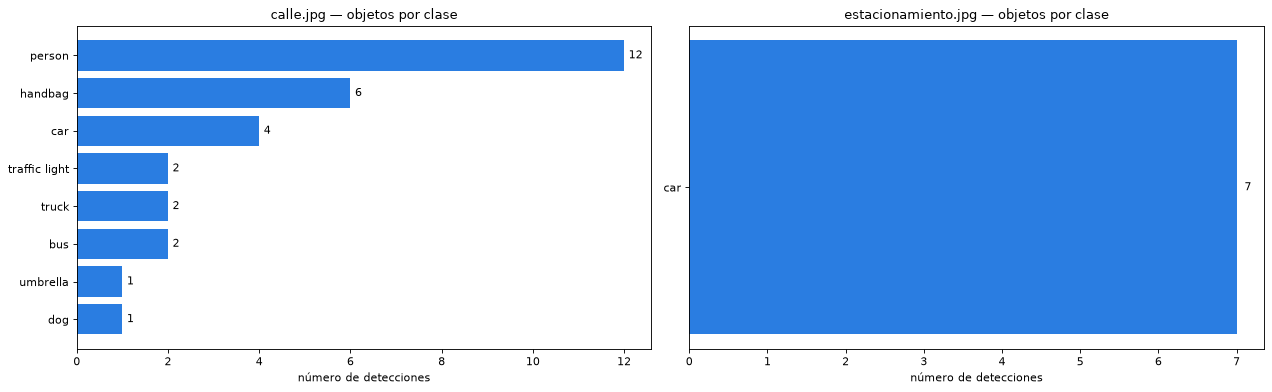

In [8]:
fig, ax = plt.subplots(1, len(RES), figsize=(8 * len(RES), 5))
ax = np.atleast_1d(ax)
for a, (k, r) in zip(ax, RES.items()):
    cnt = r.df.clase.value_counts().sort_values()
    a.barh(cnt.index, cnt.values, color="#2a7de1")
    for i, v in enumerate(cnt.values): a.text(v + 0.1, i, str(v), va="center")
    a.set_title(f"{k} — objetos por clase"); a.set_xlabel("número de detecciones")
plt.tight_layout(); plt.show()

### 4.4 Distribución de confianza y de tamaños
Los tamaños siguen la convención de COCO: **pequeño** < 32² px, **mediano** < 96² px, **grande** ≥ 96² px, con el área normalizada a una imagen de 640 px de lado mayor (la escala de referencia de COCO). Es la categoría clave cuando se compara YOLO con los R-CNN.

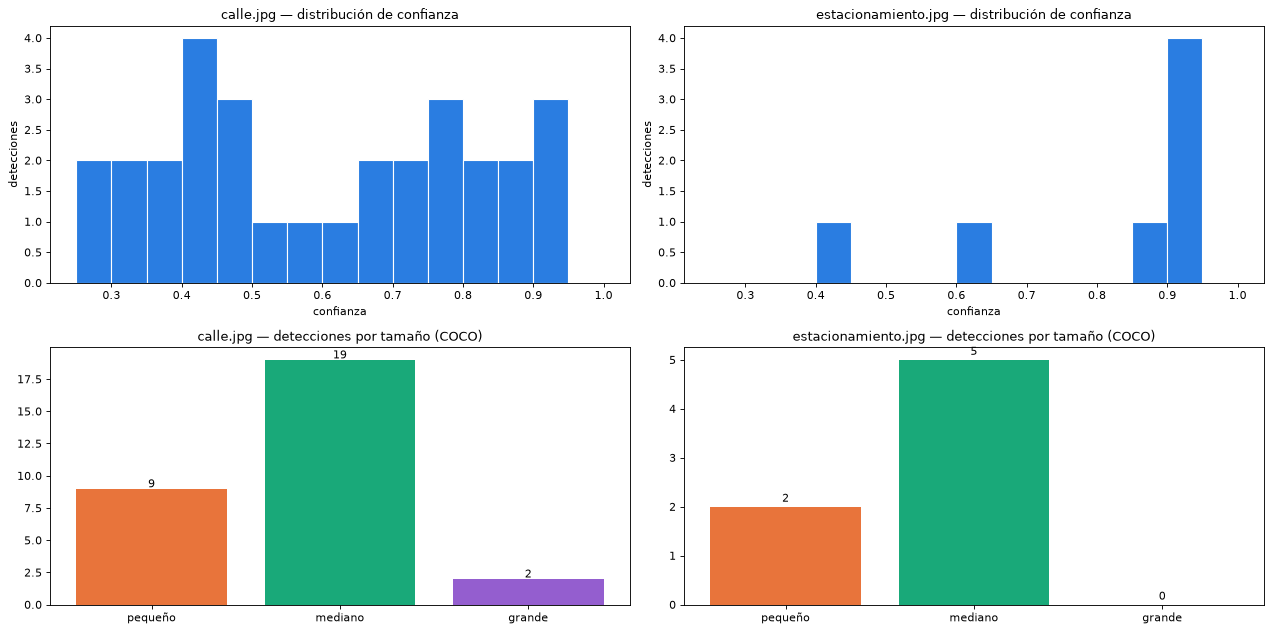

In [9]:
orden = ["pequeño", "mediano", "grande"]
fig, ax = plt.subplots(2, len(RES), figsize=(8 * len(RES), 8))
ax = np.array(ax).reshape(2, -1)
for j, (k, r) in enumerate(RES.items()):
    ax[0, j].hist(r.df.confianza, bins=np.linspace(0.25, 1, 16), color="#2a7de1", edgecolor="white")
    ax[0, j].set_title(f"{k} — distribución de confianza"); ax[0, j].set_xlabel("confianza"); ax[0, j].set_ylabel("detecciones")
    t = r.df.tamano.value_counts().reindex(orden).fillna(0)
    ax[1, j].bar(orden, t.values, color=["#e8743b", "#19a979", "#945ecf"])
    for i, v in enumerate(t.values): ax[1, j].text(i, v + 0.1, str(int(v)), ha="center")
    ax[1, j].set_title(f"{k} — detecciones por tamaño (COCO)")
plt.tight_layout(); plt.show()

### 4.5 Galería de recortes (las detecciones con más confianza)
Cada objeto detectado se recorta y se guarda en `resultados/recortes/`.

calle.jpg


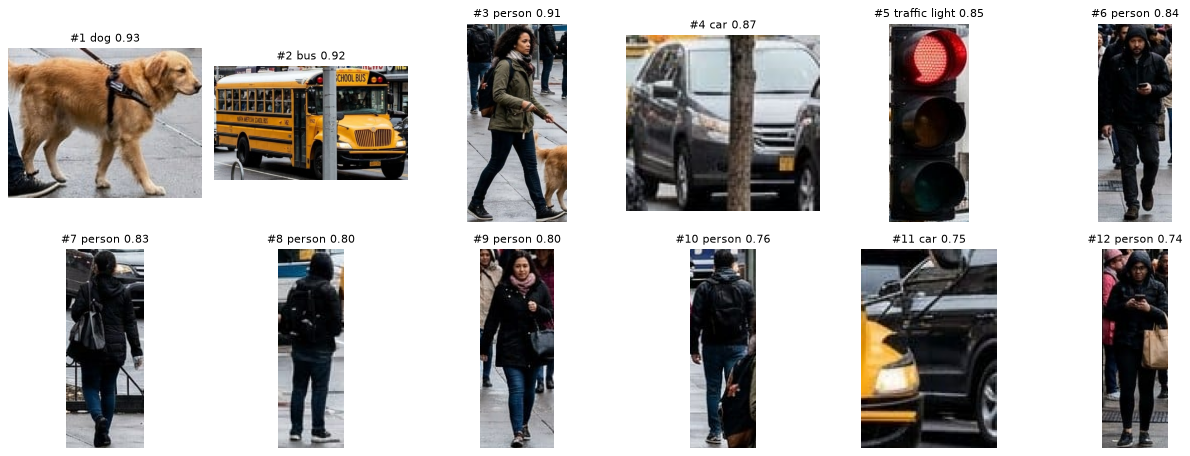

estacionamiento.jpg


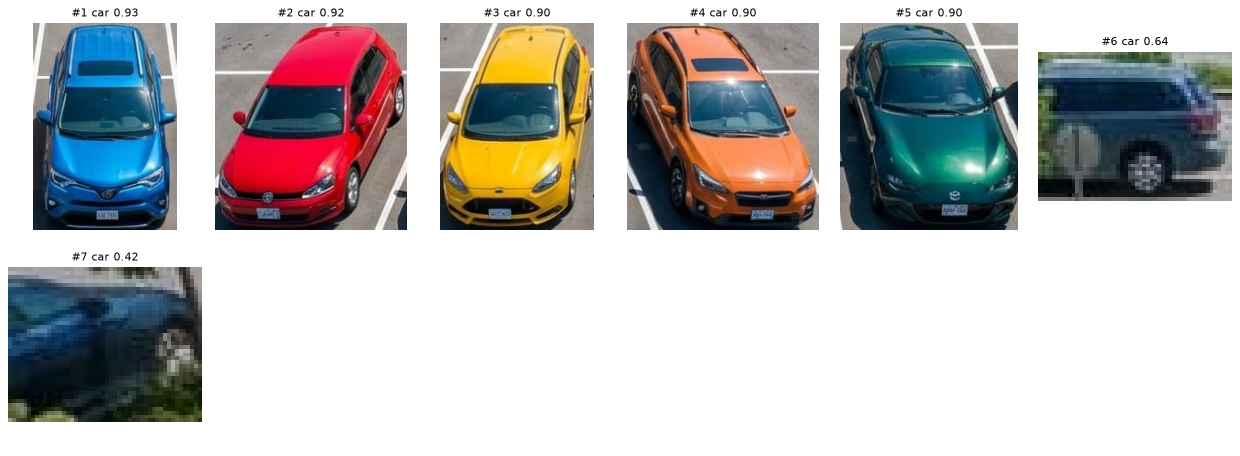

In [10]:
for k, r in RES.items():
    print(k)
    galeria_recortes(r, n=12, guardar_en=f"{SALIDA}/recortes")

## 5. Experimentos con YOLO
Cuatro variables que determinan el compromiso **velocidad ↔ precisión** del detector.

### 5.1 Tamaño del modelo: YOLO11 n / s / m

,modelo,imagen,detecciones,confianza media,tiempo mediano (ms)
0,yolo11n,calle.jpg,20,0.598,49.9
1,yolo11n,estacionamiento.jpg,7,0.507,49.4
2,yolo11s,calle.jpg,30,0.607,129.4
3,yolo11s,estacionamiento.jpg,7,0.803,136.3
4,yolo11m,calle.jpg,34,0.606,305.1
5,yolo11m,estacionamiento.jpg,7,0.786,301.6


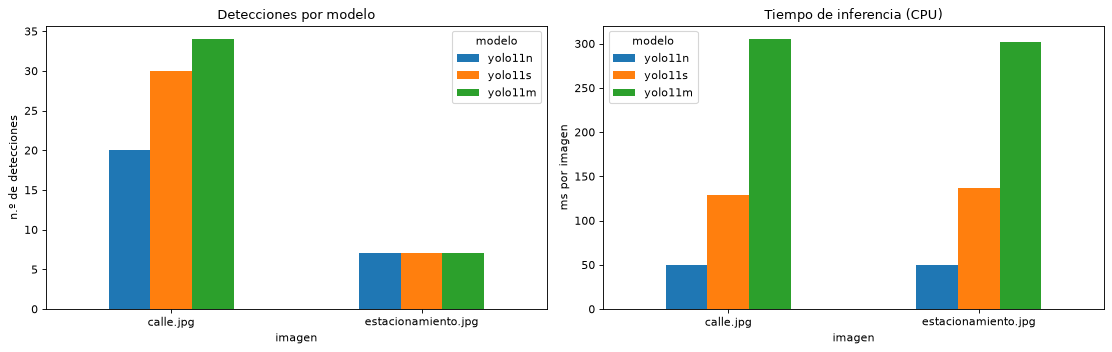

In [11]:
MODELOS = ["yolo11n.pt", "yolo11s.pt", "yolo11m.pt"]
filas = []
for w in MODELOS:
    d = yolo if w == MODELO_PRINCIPAL else DetectorYOLO(w)
    for p in IMAGES:
        r = d.detect(p)
        filas.append({"modelo": w.replace(".pt", ""), "imagen": os.path.basename(p), "detecciones": len(r.df),
                      "confianza media": round(r.df.confianza.mean(), 3),
                      "tiempo mediano (ms)": round(d.tiempo_mediano(p), 1)})
exp_modelos = pd.DataFrame(filas)
display(exp_modelos)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
exp_modelos.pivot(index="imagen", columns="modelo", values="detecciones")[["yolo11n", "yolo11s", "yolo11m"]].plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Detecciones por modelo"); ax[0].set_ylabel("n.º de detecciones")
exp_modelos.pivot(index="imagen", columns="modelo", values="tiempo mediano (ms)")[["yolo11n", "yolo11s", "yolo11m"]].plot.bar(ax=ax[1], rot=0)
ax[1].set_title(f"Tiempo de inferencia ({'GPU' if DEVICE == 0 else 'CPU'})"); ax[1].set_ylabel("ms por imagen")
plt.tight_layout(); plt.show()

### 5.2 Umbral de confianza
Un umbral bajo detecta más (más falsos positivos); uno alto detecta menos pero con más certeza.

imagen,calle.jpg,estacionamiento.jpg
umbral,,
0.10,53,7
0.25,30,7
0.40,24,7
0.50,17,6
0.70,12,5
0.90,3,4


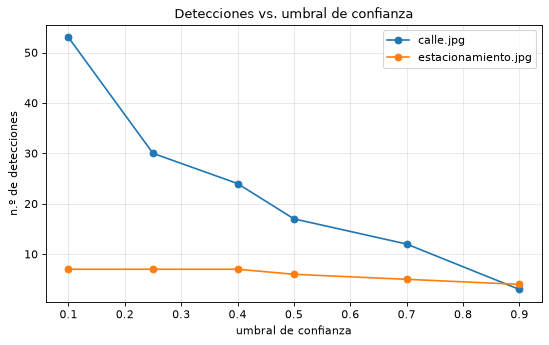

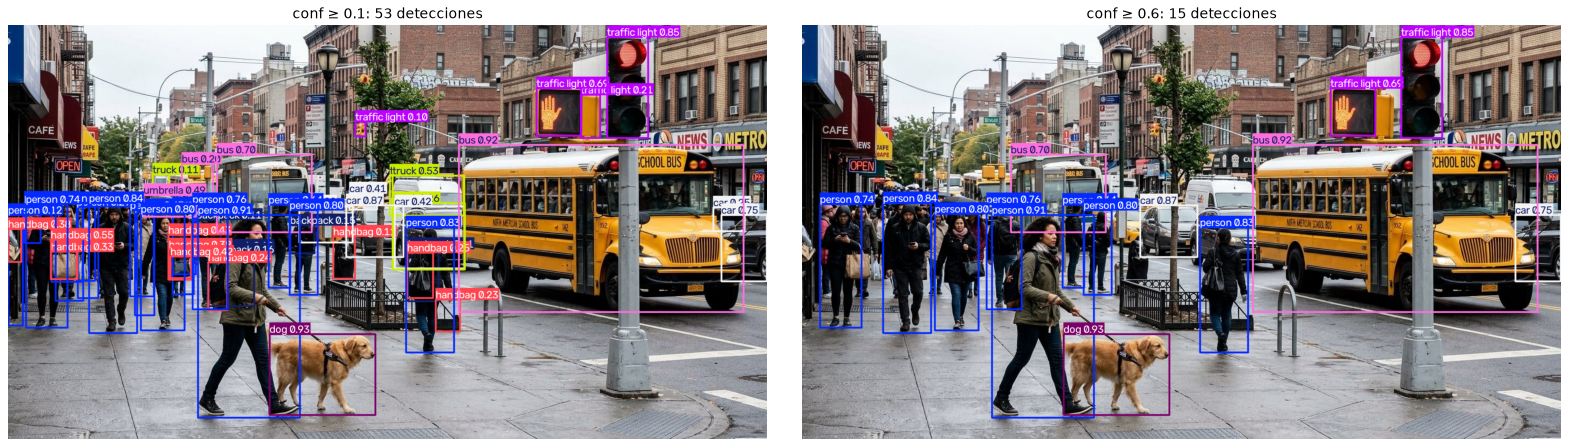

In [12]:
umbrales = [0.10, 0.25, 0.40, 0.50, 0.70, 0.90]
filas = [{"umbral": u, "imagen": os.path.basename(p), "detecciones": len(yolo.detect(p, conf=u).df)}
         for u in umbrales for p in IMAGES]
exp_conf = pd.DataFrame(filas)
display(exp_conf.pivot(index="umbral", columns="imagen", values="detecciones"))

plt.figure(figsize=(8, 4.5))
for img, g in exp_conf.groupby("imagen"): plt.plot(g.umbral, g.detecciones, "o-", label=img)
plt.xlabel("umbral de confianza"); plt.ylabel("n.º de detecciones"); plt.title("Detecciones vs. umbral de confianza")
plt.grid(alpha=.3); plt.legend(); plt.show()

# Efecto visual en la calle: umbral bajo vs. alto
calle = [p for p in IMAGES if "calle" in p][0]
fig, ax = plt.subplots(1, 2, figsize=(20, 5.5))
for a, u in zip(ax, [0.10, 0.60]):
    r = yolo.detect(calle, conf=u); a.imshow(r.anotada_rgb); a.axis("off"); a.set_title(f"conf ≥ {u}: {len(r.df)} detecciones", fontsize=13)
plt.tight_layout(); plt.show()

### 5.3 NMS: umbral IoU y NMS agnóstico a la clase
El NMS descarta cajas duplicadas. Con `agnostic=True` también se elimina la superposición **entre clases distintas** (p. ej. un *car* y un *truck* sobre el mismo vehículo).

,imagen,IoU NMS,agnóstico,detecciones
0,calle.jpg,0.3,False,26
1,calle.jpg,0.5,False,27
2,calle.jpg,0.7,False,30
3,calle.jpg,0.9,False,43
4,calle.jpg,0.7,True,29
5,estacionamiento.jpg,0.3,False,7
6,estacionamiento.jpg,0.5,False,7
7,estacionamiento.jpg,0.7,False,7
8,estacionamiento.jpg,0.9,False,7
9,estacionamiento.jpg,0.7,True,7


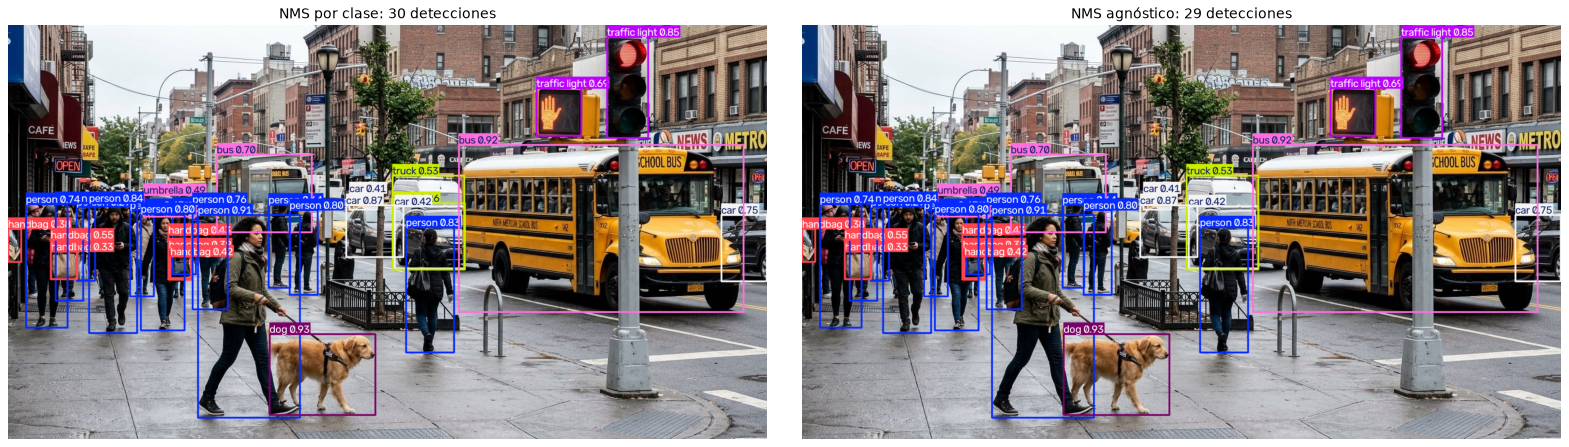

In [13]:
filas = []
for p in IMAGES:
    for iou in [0.30, 0.50, 0.70, 0.90]:
        filas.append({"imagen": os.path.basename(p), "IoU NMS": iou, "agnóstico": False, "detecciones": len(yolo.detect(p, iou=iou).df)})
    filas.append({"imagen": os.path.basename(p), "IoU NMS": 0.70, "agnóstico": True, "detecciones": len(yolo.detect(p, iou=0.70, agnostic=True).df)})
display(pd.DataFrame(filas))

fig, ax = plt.subplots(1, 2, figsize=(20, 5.5))
for a, ag in zip(ax, [False, True]):
    r = yolo.detect(calle, agnostic=ag); a.imshow(r.anotada_rgb); a.axis("off")
    a.set_title(f"NMS {'agnóstico' if ag else 'por clase'}: {len(r.df)} detecciones", fontsize=13)
plt.tight_layout(); plt.show()

### 5.4 Resolución de entrada (`imgsz`)
Los objetos pequeños (peatones lejanos) se benefician de mayor resolución, a costa de más cómputo.

,imgsz,imagen,detecciones,pequeños,tiempo (ms)
0,320,calle.jpg,17,1,44.8
1,320,estacionamiento.jpg,5,0,44.5
2,640,calle.jpg,30,9,137.5
3,640,estacionamiento.jpg,7,2,146.7
4,1280,calle.jpg,45,22,592.0
5,1280,estacionamiento.jpg,7,2,487.9


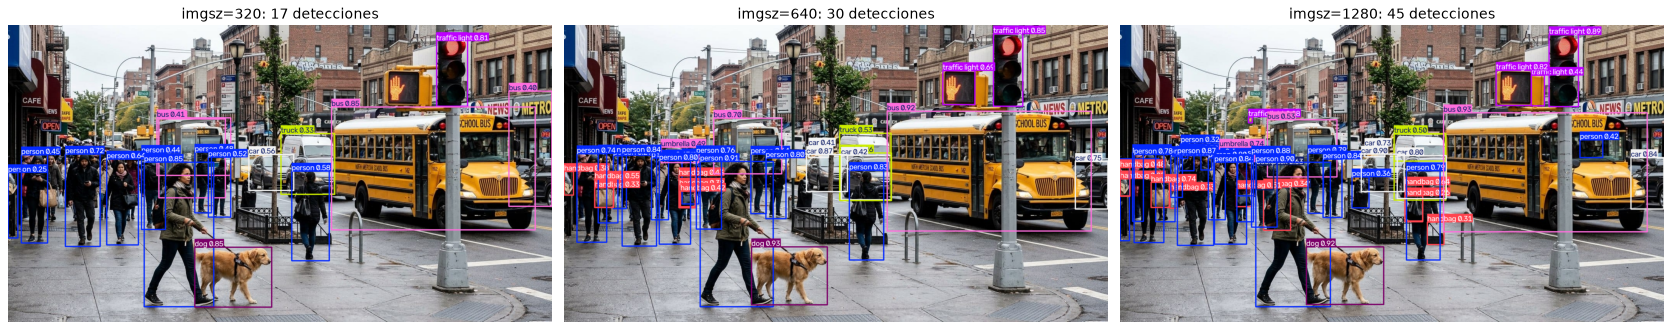

In [14]:
filas = []
for sz in [320, 640, 1280]:
    for p in IMAGES:
        r = yolo.detect(p, imgsz=sz)
        filas.append({"imgsz": sz, "imagen": os.path.basename(p), "detecciones": len(r.df),
                      "pequeños": int((r.df.tamano == "pequeño").sum()), "tiempo (ms)": round(yolo.tiempo_mediano(p, imgsz=sz), 1)})
exp_sz = pd.DataFrame(filas); display(exp_sz)

fig, ax = plt.subplots(1, 3, figsize=(21, 4.8))
for a, sz in zip(ax, [320, 640, 1280]):
    r = yolo.detect(calle, imgsz=sz); a.imshow(r.anotada_rgb); a.axis("off"); a.set_title(f"imgsz={sz}: {len(r.df)} detecciones", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Casos de uso sobre las imágenes
La detección se convierte en información útil agrupando clases y analizando posiciones.

### 6.1 Calle: peatones, vehículos, mascotas y señalización

,personas,vehículos,mascotas,accesorios,señalización
calle.jpg,12,8,1,7,2
estacionamiento.jpg,0,7,0,0,0


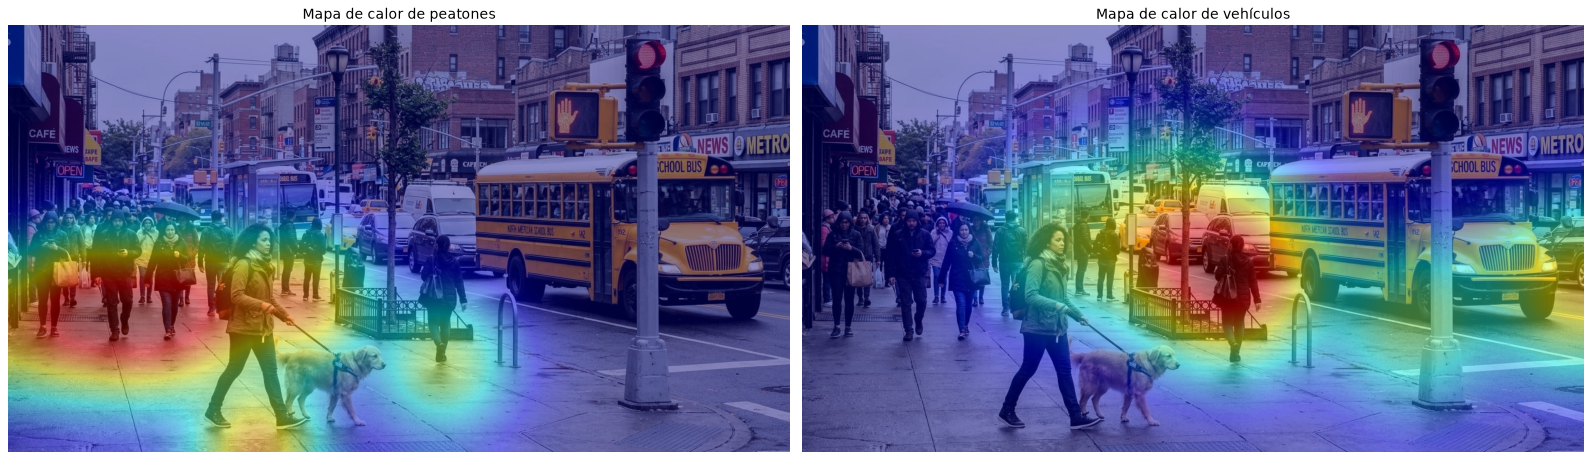

Peatones detectados: 12 · el 8% son de tamaño 'pequeño' (lejanos).


In [15]:
GRUPOS = {
    "personas":      ["person"],
    "vehículos":     ["car", "bus", "truck", "motorcycle", "bicycle"],
    "mascotas":      ["dog", "cat"],
    "accesorios":    ["handbag", "backpack", "umbrella", "suitcase"],
    "señalización":  ["traffic light", "stop sign"],
}
def resumen_grupos(res):
    return {g: int(res.df.clase.isin(cl).sum()) for g, cl in GRUPOS.items()}

tabla_grupos = pd.DataFrame({k: resumen_grupos(r) for k, r in RES.items()}).T
display(tabla_grupos)

def mapa_calor(res, clases, sigma=70, alpha=0.45, gamma=0.5):
    h, w = res.imagen_rgb.shape[:2]
    m = np.zeros((h, w), np.float32)
    for _, d in res.df[res.df.clase.isin(clases)].iterrows():       # se usa el punto de apoyo (pies / base)
        m[min(int(d.y2), h - 1), min(int((d.x1 + d.x2) / 2), w - 1)] += 1
    m = cv2.GaussianBlur(m, (0, 0), sigma); m = (m / (m.max() + 1e-9)) ** gamma   # gamma<1 realza zonas de menor densidad
    calor = cv2.applyColorMap((m * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return cv2.addWeighted(res.imagen_rgb, 1 - alpha, calor, alpha, 0)

r_calle = RES[os.path.basename(calle)]
fig, ax = plt.subplots(1, 2, figsize=(20, 5.8))
ax[0].imshow(mapa_calor(r_calle, ["person"])); ax[0].set_title("Mapa de calor de peatones", fontsize=13)
ax[1].imshow(mapa_calor(r_calle, GRUPOS["vehículos"], sigma=90)); ax[1].set_title("Mapa de calor de vehículos", fontsize=13)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

n_per = resumen_grupos(r_calle)["personas"]
print(f"Peatones detectados: {n_per} · el {100*(r_calle.df[r_calle.df.clase=='person'].tamano=='pequeño').mean():.0f}% son de tamaño 'pequeño' (lejanos).")

### 6.2 Estacionamiento: ocupación de plazas y color de cada vehículo
Los vehículos de la fila frontal (los que están sobre las plazas marcadas) se numeran de izquierda a derecha y se identifica su color dominante en el espacio HSV; los de fondo se informan aparte.

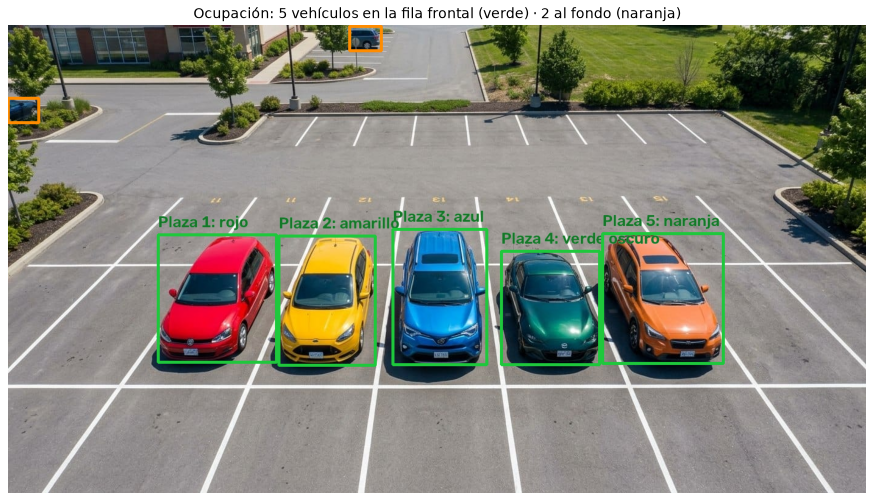

,plaza,clase,color,confianza
0,1,car,rojo,0.924
1,2,car,amarillo,0.905
2,3,car,azul,0.925
3,4,car,verde oscuro,0.896
4,5,car,naranja,0.904


In [16]:
def nombre_color(crop_rgb):
    """Color dominante del vehículo en HSV. Se usa la franja del capó (parte baja y central del recorte,
    porque en esta vista los autos miran hacia la cámara) para no mezclar el reflejo del parabrisas."""
    h, w = crop_rgb.shape[:2]
    c = crop_rgb[int(h * .58):int(h * .85), int(w * .30):int(w * .70)]
    hsv = cv2.cvtColor(c, cv2.COLOR_RGB2HSV).reshape(-1, 3).astype(int)
    vivos = hsv[(hsv[:, 1] > 60) & (hsv[:, 2] > 30)]
    if len(vivos) < 20:
        v = hsv[:, 2].mean(); return "negro" if v < 60 else ("blanco" if v > 190 else "gris")
    tono = np.median((vivos[:, 0] + 10) % 180)        # se desplaza el tono para unir los dos extremos del rojo
    brillo = np.median(vivos[:, 2])
    for lim, n in [(15, "rojo"), (32, "naranja"), (45, "amarillo"), (107, "verde"), (145, "azul"), (170, "morado")]:
        if tono < lim:
            return n + (" oscuro" if brillo < 130 else "")
    return "rosa"

def analizar_estacionamiento(res, frac_y=0.35):
    h = res.imagen_rgb.shape[0]
    autos = res.df[res.df.clase.isin(["car", "truck", "bus"])].copy()
    autos["fila"] = np.where((autos.y1 + autos.y2) / 2 > frac_y * h, "frontal", "fondo")
    autos["color"] = [nombre_color(res.imagen_rgb[int(d.y1):int(d.y2), int(d.x1):int(d.x2)]) for _, d in autos.iterrows()]
    frente = autos[autos.fila == "frontal"].sort_values("x1").reset_index(drop=True)
    frente["plaza"] = np.arange(1, len(frente) + 1)

    img = res.imagen_rgb.copy()
    for _, d in frente.iterrows():
        p1, p2 = (int(d.x1), int(d.y1)), (int(d.x2), int(d.y2))
        cv2.rectangle(img, p1, p2, (30, 200, 60), 4)
        cv2.putText(img, f"Plaza {d.plaza}: {d.color}", (p1[0], p1[1] - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 4)
        cv2.putText(img, f"Plaza {d.plaza}: {d.color}", (p1[0], p1[1] - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (20, 120, 40), 2)
    for _, d in autos[autos.fila == "fondo"].iterrows():
        cv2.rectangle(img, (int(d.x1), int(d.y1)), (int(d.x2), int(d.y2)), (255, 140, 0), 3)
    return img, frente, autos[autos.fila == "fondo"]

park = [p for p in IMAGES if "estacion" in p][0]
img_park, frente, fondo = analizar_estacionamiento(RES[os.path.basename(park)])
plt.figure(figsize=(14, 7.6)); plt.imshow(img_park); plt.axis("off")
plt.title(f"Ocupación: {len(frente)} vehículos en la fila frontal (verde) · {len(fondo)} al fondo (naranja)", fontsize=13); plt.show()
display(frente[["plaza", "clase", "color", "confianza"]])

## 7. Comparación con Faster R-CNN (perspectiva R-CNN)
Se ejecuta **Faster R-CNN ResNet-50 FPN** (torchvision, preentrenado en COCO) sobre **las mismas imágenes** y con el **mismo umbral de confianza**, y se emparejan sus detecciones con las de YOLO mediante **IoU ≥ 0.5 y misma clase**.

In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.io import read_image
from torchvision.utils import draw_bounding_boxes

try:
    pesos_rcnn = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    dev_t = "cuda" if torch.cuda.is_available() else "cpu"
    rcnn = fasterrcnn_resnet50_fpn(weights=pesos_rcnn, box_score_thresh=CONF).to(dev_t).eval()
    CATS, prep = pesos_rcnn.meta["categories"], pesos_rcnn.transforms()
    RCNN_OK = True
except Exception as e:
    RCNN_OK = False
    print("No se pudieron cargar los pesos de Faster R-CNN:", e)

def sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()

@torch.no_grad()
def detectar_rcnn(path):
    img = read_image(path)[:3]
    x = prep(img).to(dev_t)
    sync(); t0 = time.perf_counter()
    out = rcnn([x])[0]; sync()
    ms = (time.perf_counter() - t0) * 1000
    b = out["boxes"].cpu().numpy()
    df = pd.DataFrame({"clase": [CATS[i] for i in out["labels"].cpu()], "confianza": out["scores"].cpu().numpy().round(3),
                       "x1": b[:, 0], "y1": b[:, 1], "x2": b[:, 2], "y2": b[:, 3]})
    etiquetas = [f"{c} {s:.2f}" for c, s in zip(df.clase, df.confianza)]
    dibujo = draw_bounding_boxes(img, out["boxes"].cpu(), etiquetas, width=3, font_size=14).permute(1, 2, 0).numpy()
    return df, dibujo, ms

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0

def emparejar(dfa, dfb, umbral=0.5):
    """Emparejamiento voraz por IoU (misma clase). Devuelve nº de coincidencias."""
    usados, n = set(), 0
    for _, a in dfa.iterrows():
        mejor, j_mejor = 0, None
        for j, b in dfb.iterrows():
            if j in usados or a.clase != b.clase: continue
            v = iou((a.x1, a.y1, a.x2, a.y2), (b.x1, b.y1, b.x2, b.y2))
            if v > mejor: mejor, j_mejor = v, j
        if j_mejor is not None and mejor >= umbral: usados.add(j_mejor); n += 1
    return n

if RCNN_OK:
    detectar_rcnn(IMAGES[0])                         # calentamiento
    filas = []
    for p in IMAGES:
        nombre = os.path.basename(p)
        df_r, dibujo, ms_r = detectar_rcnn(p)
        ms_r = float(np.median([ms_r] + [detectar_rcnn(p)[2] for _ in range(2)]))
        y = RES[nombre]; ms_y = yolo.tiempo_mediano(p)
        coinc = emparejar(y.df, df_r)
        fig, ax = plt.subplots(1, 2, figsize=(20, 6))
        ax[0].imshow(y.anotada_rgb);  ax[0].set_title(f"YOLO ({y.modelo}) — {len(y.df)} detecciones · {ms_y:.0f} ms", fontsize=13)
        ax[1].imshow(dibujo);         ax[1].set_title(f"Faster R-CNN — {len(df_r)} detecciones · {ms_r:.0f} ms", fontsize=13)
        for a in ax: a.axis("off")
        plt.tight_layout(); plt.show()
        filas.append({"imagen": nombre, "det. YOLO": len(y.df), "det. R-CNN": len(df_r), "coinciden (IoU≥0.5)": coinc,
                      "solo YOLO": len(y.df) - coinc, "solo R-CNN": len(df_r) - coinc,
                      "tiempo YOLO (ms)": round(ms_y, 1), "tiempo R-CNN (ms)": round(ms_r, 1),
                      "R-CNN / YOLO (×)": round(ms_r / ms_y, 1)})
    comp = pd.DataFrame(filas); display(comp)

## 8. Aplicación interactiva (Gradio)
Interfaz web con la que se puede **subir cualquier imagen**, elegir el modelo YOLO, ajustar confianza / IoU / resolución y filtrar clases. Al ejecutar la celda aparece una URL pública temporal (`share=True`) y la interfaz también se muestra dentro del cuaderno. Las dos imágenes de la actividad están cargadas como ejemplos.

In [ ]:
import gradio as gr

DETECTORES = {MODELO_PRINCIPAL: yolo}
def get_detector(w):
    if w not in DETECTORES: DETECTORES[w] = DetectorYOLO(w)
    return DETECTORES[w]

def app_detectar(imagen_rgb, modelo, conf, iou_nms, imgsz, clases, agnostico):
    if imagen_rgb is None: return None, None, "Sube una imagen."
    ids = [k for k, v in yolo.names.items() if v in (clases or [])] or None
    r = get_detector(modelo).detect(imagen_rgb[..., ::-1].copy(), conf=conf, iou=iou_nms, imgsz=int(imgsz),
                                    clases=ids, agnostic=agnostico, nombre="subida")
    cnt = ", ".join(f"{v} {k}" for k, v in Counter(r.df.clase).most_common()) or "sin detecciones"
    return r.anotada_rgb, r.df.drop(columns=["tamano"]), f"**{len(r.df)} objetos** — {cnt}  ·  ⏱ {r.tiempo_ms:.0f} ms ({modelo})"

with gr.Blocks(title="Detección de objetos con YOLO") as demo:
    gr.Markdown("# 🔎 Detección de objetos con YOLO\nActividad 06 — Segunda unidad")
    with gr.Row():
        with gr.Column():
            entrada = gr.Image(type="numpy", label="Imagen")
            modelo = gr.Dropdown(["yolo11n.pt", "yolo11s.pt", "yolo11m.pt"], value=MODELO_PRINCIPAL, label="Modelo YOLO11")
            conf = gr.Slider(0.05, 0.95, CONF, step=0.05, label="Umbral de confianza")
            iou_s = gr.Slider(0.1, 0.95, IOU, step=0.05, label="IoU para NMS")
            imgsz = gr.Radio([320, 640, 1280], value=640, label="Resolución de entrada")
            clases = gr.Dropdown(list(yolo.names.values()), multiselect=True, label="Filtrar clases (vacío = todas)")
            agn = gr.Checkbox(False, label="NMS agnóstico a la clase")
            boton = gr.Button("Detectar", variant="primary")
        with gr.Column():
            salida = gr.Image(label="Resultado")
            texto = gr.Markdown()
            tabla = gr.Dataframe(label="Detecciones")
    boton.click(app_detectar, [entrada, modelo, conf, iou_s, imgsz, clases, agn], [salida, tabla, texto])
    gr.Examples([[os.path.join(IMG_DIR, "calle.jpg")], [os.path.join(IMG_DIR, "estacionamiento.jpg")]], inputs=entrada)

demo.launch(share=True, debug=False)

## 9. Exportación de resultados
Imágenes anotadas, tabla de detecciones (CSV), resumen (JSON) y un ZIP descargable.

In [19]:
os.makedirs(f"{SALIDA}/anotadas", exist_ok=True)
frames = []
for k, r in RES.items():
    cv2.imwrite(f"{SALIDA}/anotadas/{k[:-4]}_yolo.jpg", r.anotada_rgb[..., ::-1])
    frames.append(r.df.assign(imagen=k, modelo=r.modelo))
cv2.imwrite(f"{SALIDA}/anotadas/estacionamiento_ocupacion.jpg", img_park[..., ::-1])
pd.concat(frames).to_csv(f"{SALIDA}/detecciones.csv", index=False)
json.dump({k: {"modelo": r.modelo, "parametros": r.params, "detecciones": len(r.df),
               "por_clase": dict(Counter(r.df.clase)), "tiempo_ms": round(r.tiempo_ms, 1)} for k, r in RES.items()},
          open(f"{SALIDA}/resumen.json", "w"), indent=2, ensure_ascii=False)

with zipfile.ZipFile("resultados_actividad06.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for ruta in glob.glob(f"{SALIDA}/**/*", recursive=True):
        if os.path.isfile(ruta): z.write(ruta)
archivos = sorted(f for f in glob.glob(f"{SALIDA}/**/*", recursive=True) if os.path.isfile(f))
print(f"Archivos generados ({len(archivos)}) en '{SALIDA}/' + resultados_actividad06.zip:")
for f in archivos: print("  ", f)
try:
    from google.colab import files; files.download("resultados_actividad06.zip")
except ImportError:
    pass

Archivos generados (24) en 'resultados/' + resultados_actividad06.zip:
   resultados/anotadas/calle_yolo.jpg
   resultados/anotadas/estacionamiento_ocupacion.jpg
   resultados/anotadas/estacionamiento_yolo.jpg
   resultados/detecciones.csv
   resultados/recortes/calle_01_dog.jpg
   resultados/recortes/calle_02_bus.jpg
   resultados/recortes/calle_03_person.jpg
   resultados/recortes/calle_04_car.jpg
   resultados/recortes/calle_05_traffic light.jpg
   resultados/recortes/calle_06_person.jpg
   resultados/recortes/calle_07_person.jpg
   resultados/recortes/calle_08_person.jpg
   resultados/recortes/calle_09_person.jpg
   resultados/recortes/calle_10_person.jpg
   resultados/recortes/calle_11_car.jpg
   resultados/recortes/calle_12_person.jpg
   resultados/recortes/estacionamiento_01_car.jpg
   resultados/recortes/estacionamiento_02_car.jpg
   resultados/recortes/estacionamiento_03_car.jpg
   resultados/recortes/estacionamiento_04_car.jpg
   resultados/recortes/estacionamiento_05_car.jpg

## 10. Conclusiones

In [20]:
# Resumen generado automáticamente a partir de los resultados de ESTA ejecución
disp = "GPU" if DEVICE == 0 else "CPU"
lineas = [f"**Resultados de esta ejecución ({disp}, {MODELO_PRINCIPAL}, conf={CONF}):**\n"]
for k, r in RES.items():
    top = ", ".join(f"{v} {c}" for c, v in Counter(r.df.clase).most_common(5))
    peq = int((r.df.tamano == "pequeño").sum())
    lineas.append(f"- **{k}**: {len(r.df)} objetos en {r.tiempo_ms:.0f} ms (≈ {1000/r.tiempo_ms:.1f} FPS). Principales: {top}. Pequeños: {peq}.")
n, s, m = (exp_modelos[exp_modelos.modelo == x]["tiempo mediano (ms)"].mean() for x in ["yolo11n", "yolo11s", "yolo11m"])
lineas.append(f"- **Tamaño del modelo**: tiempo medio n = {n:.0f} ms · s = {s:.0f} ms · m = {m:.0f} ms (m es {m/n:.1f}× más lento que n).")
lineas.append(f"- **Estacionamiento**: {len(frente)} vehículos en la fila frontal ({', '.join(frente.color)}) y {len(fondo)} al fondo.")
if "comp" in globals():
    lineas.append(f"- **Faster R-CNN vs YOLO**: R-CNN fue en promedio {comp['R-CNN / YOLO (×)'].mean():.1f}× más lento; coincidencias medias {comp['coinciden (IoU≥0.5)'].mean():.0f} de {comp['det. YOLO'].mean():.0f} detecciones de YOLO.")
display(Markdown("\n".join(lineas)))

**Resultados de esta ejecución (CPU, yolo11s.pt, conf=0.25):**

- **calle.jpg**: 30 objetos en 151 ms (≈ 6.6 FPS). Principales: 12 person, 6 handbag, 4 car, 2 bus, 2 traffic light. Pequeños: 9.
- **estacionamiento.jpg**: 7 objetos en 134 ms (≈ 7.4 FPS). Principales: 7 car. Pequeños: 2.
- **Tamaño del modelo**: tiempo medio n = 50 ms · s = 133 ms · m = 303 ms (m es 6.1× más lento que n).
- **Estacionamiento**: 5 vehículos en la fila frontal (rojo, amarillo, azul, verde oscuro, naranja) y 2 al fondo.

### Análisis

1. **YOLO cumple la tarea de forma directa y rápida.** Una sola pasada por la red entrega cajas, clases y confianzas. En la **calle** (escena compleja: multitud, oclusiones, personas lejanas, bolsos, un autobús escolar, taxis y semáforos) el modelo identifica personas, vehículos, el perro y los semáforos; en el **estacionamiento** (escena simple, objetos grandes y separados) detecta los cinco autos de la fila frontal con confianza alta, además de los vehículos lejanos del fondo.
2. **La dificultad depende de la escena, no solo del modelo.** Los errores y las dudas aparecen en la calle: objetos pequeños y parcialmente ocultos (bolsos, peatones del fondo) con confianzas bajas, y cajas casi duplicadas entre clases cercanas (*car* / *truck* sobre el mismo vehículo). El NMS agnóstico a la clase elimina parte de ese solapamiento entre clases (ver 5.3), mientras que un IoU de NMS muy alto (0.9) deja pasar **muchas cajas duplicadas**.
3. **Los hiperparámetros controlan el compromiso.** Subir `conf` elimina falsos positivos pero pierde objetos difíciles (en la calle el número de detecciones cae con fuerza al pasar de 0.10 a 0.90, mientras que en el estacionamiento los 5 autos frontales se mantienen hasta umbrales altos); subir `imgsz` ayuda con los objetos pequeños a costa de tiempo; pasar de *n* a *m* aumenta la capacidad (y la latencia).
4. **Perspectiva R-CNN vs YOLO.** Faster R-CNN separa *proponer* y *clasificar*: suele ser más lento porque la segunda etapa se aplica por región, y aporta robustez en objetos pequeños o muy próximos. YOLO evalúa todo en una pasada y ve la imagen completa, lo que lo hace idóneo para **tiempo real** y despliegue en dispositivos limitados; con cuellos multiescala y mayor resolución la brecha de precisión se ha reducido mucho.
5. **Elección práctica.** Latencia crítica, video o *edge* → **YOLO**. Máxima calidad sin restricción de tiempo, o *datasets* con muchos objetos diminutos → un **R-CNN** (o un YOLO grande a alta resolución) puede compensar.

**Limitaciones:** los modelos están preentrenados en COCO (80 clases); no se midió mAP porque las imágenes no tienen anotaciones de referencia (*ground truth*). Para una evaluación formal se necesitaría etiquetar manualmente las imágenes. La comparación con Faster R-CNN se hace con el **mismo umbral de confianza** y el emparejamiento por IoU describe *coincidencia*, no *exactitud*.